# MediSense AI - Exploratory Data Analysis

## 1. Dataset Understanding

Objective:
To understand the disease-symptom dataset, explore its structure,
identify data quality issues, and prepare it for machine learning.

In [1]:
# Importing required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display all columns
pd.set_option('display.max_columns', None)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Loading the dataset

df = pd.read_csv("../data/raw/dataset.csv")

# Display first five records
df.head()

,Disease,Symptom_1,Symptom_2,Symptom_3,Symptom_4,Symptom_5,Symptom_6,Symptom_7,Symptom_8,Symptom_9,Symptom_10,Symptom_11,Symptom_12,Symptom_13,Symptom_14,Symptom_15,Symptom_16,Symptom_17
0,Fungal infection,itching,skin_rash,nodal_skin_eruptions,dischromic _patches,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Fungal infection,skin_rash,nodal_skin_eruptions,dischromic _patches,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Fungal infection,itching,nodal_skin_eruptions,dischromic _patches,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Fungal infection,itching,skin_rash,dischromic _patches,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Fungal infection,itching,skin_rash,nodal_skin_eruptions,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
# Check the number of rows and columns

print("Dataset Shape:", df.shape)

print("\nNumber of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Dataset Shape: (4920, 18)

Number of Rows: 4920
Number of Columns: 18


In [4]:
# Display all column names

print("Column Names:")
print(df.columns.tolist())

# Check data types and non-null values
print("\nDataset Information:")
df.info()

Column Names:
['Disease', 'Symptom_1', 'Symptom_2', 'Symptom_3', 'Symptom_4', 'Symptom_5', 'Symptom_6', 'Symptom_7', 'Symptom_8', 'Symptom_9', 'Symptom_10', 'Symptom_11', 'Symptom_12', 'Symptom_13', 'Symptom_14', 'Symptom_15', 'Symptom_16', 'Symptom_17']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 4920 entries, 0 to 4919
Data columns (total 18 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Disease     4920 non-null   str  
 1   Symptom_1   4920 non-null   str  
 2   Symptom_2   4920 non-null   str  
 3   Symptom_3   4920 non-null   str  
 4   Symptom_4   4572 non-null   str  
 5   Symptom_5   3714 non-null   str  
 6   Symptom_6   2934 non-null   str  
 7   Symptom_7   2268 non-null   str  
 8   Symptom_8   1944 non-null   str  
 9   Symptom_9   1692 non-null   str  
 10  Symptom_10  1512 non-null   str  
 11  Symptom_11  1194 non-null   str  
 12  Symptom_12  744 non-null    str  
 13  Symptom_13  504 non-null    str  
 14

In [5]:
# Count records for each disease

disease_counts = df["Disease"].value_counts()

print(disease_counts)

print("\nTotal Unique Diseases:", df["Disease"].nunique())

Disease
Fungal infection                           120
Allergy                                    120
GERD                                       120
Chronic cholestasis                        120
Drug Reaction                              120
Peptic ulcer diseae                        120
AIDS                                       120
Diabetes                                   120
Gastroenteritis                            120
Bronchial Asthma                           120
Hypertension                               120
Migraine                                   120
Cervical spondylosis                       120
Paralysis (brain hemorrhage)               120
Jaundice                                   120
Malaria                                    120
Chicken pox                                120
Dengue                                     120
Typhoid                                    120
hepatitis A                                120
Hepatitis B                                120
Hepat

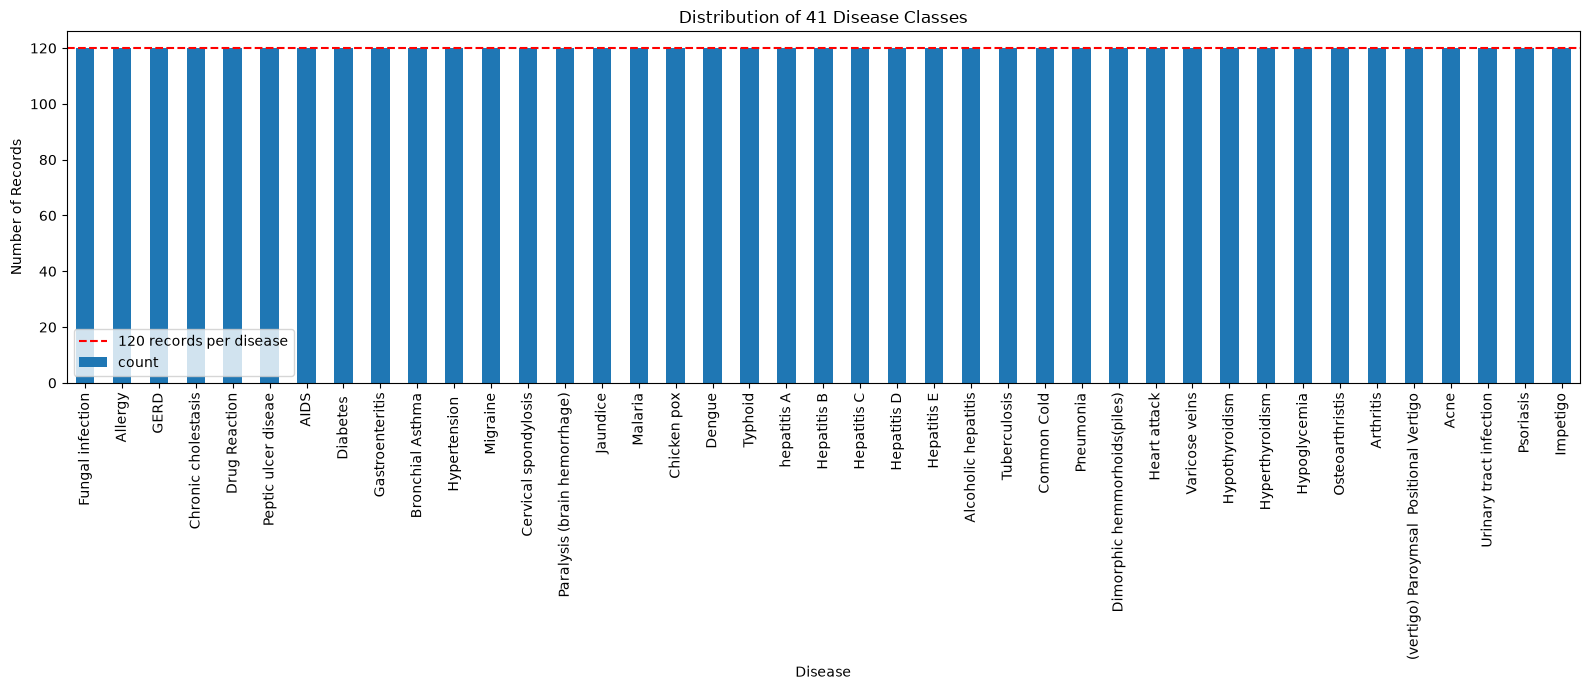

In [6]:
plt.figure(figsize=(16, 7))

disease_counts.plot(kind="bar")

plt.title("Distribution of 41 Disease Classes")
plt.xlabel("Disease")
plt.ylabel("Number of Records")
plt.xticks(rotation=90)

plt.axhline(y=120, color="red", linestyle="--",
            label="120 records per disease")

plt.legend()
plt.tight_layout()
plt.show()

In [7]:
# Check exact duplicate rows

duplicate_count = df.duplicated().sum()

print("Total Duplicate Rows:", duplicate_count)

print("Percentage of Duplicates:",
      (duplicate_count / len(df)) * 100)

Total Duplicate Rows: 4616
Percentage of Duplicates: 93.82113821138212


In [8]:
# Check duplicate records separately for each disease

duplicates_by_disease = (
    df.groupby("Disease")
      .apply(lambda x: x.duplicated().sum())
)

print(duplicates_by_disease.to_string())

Disease
(vertigo) Paroymsal  Positional Vertigo    113
AIDS                                       115
Acne                                       115
Alcoholic hepatitis                        112
Allergy                                    115
Arthritis                                  114
Bronchial Asthma                           113
Cervical spondylosis                       114
Chicken pox                                110
Chronic cholestasis                        112
Common Cold                                111
Dengue                                     110
Diabetes                                   111
Dimorphic hemmorhoids(piles)               114
Drug Reaction                              114
Fungal infection                           115
GERD                                       113
Gastroenteritis                            115
Heart attack                               115
Hepatitis B                                111
Hepatitis C                                113
Hepat

In [9]:
unique_by_disease = df.groupby("Disease").apply(
    lambda x: len(x.drop_duplicates())
)

print(unique_by_disease.to_string())

Disease
(vertigo) Paroymsal  Positional Vertigo     7
AIDS                                        5
Acne                                        5
Alcoholic hepatitis                         8
Allergy                                     5
Arthritis                                   6
Bronchial Asthma                            7
Cervical spondylosis                        6
Chicken pox                                10
Chronic cholestasis                         8
Common Cold                                 9
Dengue                                     10
Diabetes                                    9
Dimorphic hemmorhoids(piles)                6
Drug Reaction                               6
Fungal infection                            5
GERD                                        7
Gastroenteritis                             5
Heart attack                                5
Hepatitis B                                 9
Hepatitis C                                 7
Hepatitis D               

In [10]:
print("Total unique records:", unique_by_disease.sum())

print("Minimum unique records per disease:",
      unique_by_disease.min())

print("Maximum unique records per disease:",
      unique_by_disease.max())

Total unique records: 304
Minimum unique records per disease: 5
Maximum unique records per disease: 10


In [11]:
# Identify symptom columns
symptom_cols = [col for col in df.columns
                if col.startswith("Symptom_")]

# Create a sorted symptom combination for each record
df["Symptom_Set"] = df[symptom_cols].apply(
    lambda row: tuple(sorted(row.dropna())),
    axis=1
)

# Count different diseases associated with each combination
disease_per_combination = (
    df.groupby("Symptom_Set")["Disease"].nunique()
)

# Find combinations associated with multiple diseases
conflicting_combinations = disease_per_combination[
    disease_per_combination > 1
]

print("Total unique symptom combinations:",
      df["Symptom_Set"].nunique())

print("Conflicting symptom combinations:",
      len(conflicting_combinations))

Total unique symptom combinations: 304
Conflicting symptom combinations: 0


In [12]:
# Count the frequency of each symptom

symptom_cols = [
    col for col in df.columns
    if col.startswith("Symptom_")
]

symptom_frequency = (
    df[symptom_cols]
    .stack()
    .str.strip()
    .value_counts()
)

print("Total unique symptoms:", len(symptom_frequency))

print("\nTop 15 most frequent symptoms:")
print(symptom_frequency.head(15))

Total unique symptoms: 131

Top 15 most frequent symptoms:
fatigue              1932
vomiting             1914
high_fever           1362
loss_of_appetite     1152
nausea               1146
headache             1134
abdominal_pain       1032
yellowish_skin        912
yellowing_of_eyes     816
chills                798
skin_rash             786
malaise               702
chest_pain            696
joint_pain            684
itching               678
Name: count, dtype: int64


In [13]:
# Count non-missing symptoms in each record
df["Symptom_Count"] = df[symptom_cols].notna().sum(axis=1)

print("Symptom count distribution:")
print(df["Symptom_Count"].value_counts().sort_index())

Symptom count distribution:
Symptom_Count
4     348
5     858
6     780
7     666
8     324
9     252
10    180
11    318
12    450
13    240
14    198
15     66
16     48
17    120
18     72
Name: count, dtype: int64


In [14]:
# Create a long-format dataset of disease-symptom pairs

disease_symptom = df.melt(
    id_vars=["Disease"],
    value_vars=symptom_cols,
    value_name="Symptom"
)

# Remove empty symptom entries
disease_symptom = disease_symptom.dropna(subset=["Symptom"])

# Remove extra spaces
disease_symptom["Symptom"] = disease_symptom["Symptom"].str.strip()

# Count symptom occurrences for each disease
disease_symptom_count = (
    disease_symptom.groupby(["Disease", "Symptom"])
    .size()
    .reset_index(name="Frequency")
)

disease_symptom_count.head(10)

,Disease,Symptom,Frequency
0,(vertigo) Paroymsal Positional Vertigo,headache,114
1,(vertigo) Paroymsal Positional Vertigo,loss_of_balance,114
2,(vertigo) Paroymsal Positional Vertigo,nausea,114
3,(vertigo) Paroymsal Positional Vertigo,spinning_movements,108
4,(vertigo) Paroymsal Positional Vertigo,unsteadiness,114
5,(vertigo) Paroymsal Positional Vertigo,vomiting,114
6,AIDS,extra_marital_contacts,108
7,AIDS,high_fever,114
8,AIDS,muscle_wasting,108
9,AIDS,patches_in_throat,108


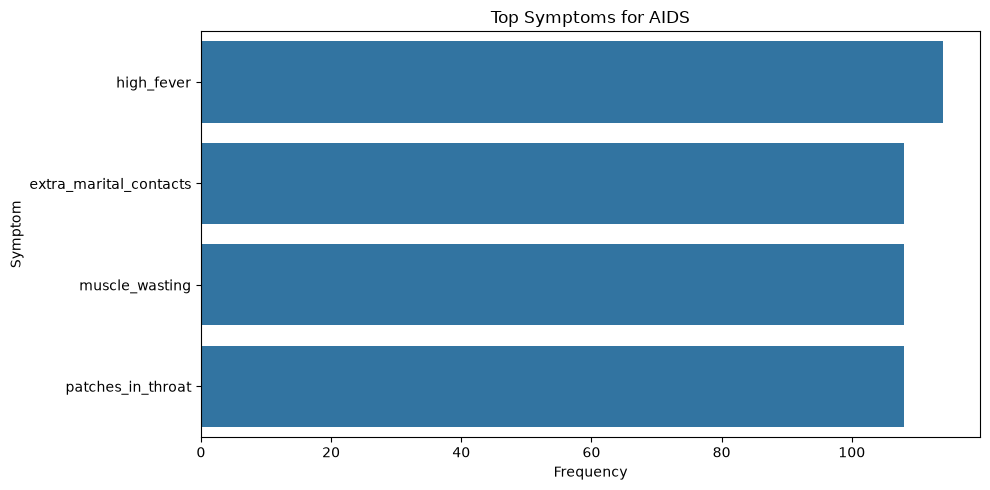

In [15]:
# Select one disease
selected_disease = "AIDS"

# Filter symptoms for that disease
disease_data = disease_symptom_count[
    disease_symptom_count["Disease"] == selected_disease
].sort_values(by="Frequency", ascending=False)

# Plot
plt.figure(figsize=(10, 5))

sns.barplot(
    data=disease_data.head(10),
    x="Frequency",
    y="Symptom"
)

plt.title(f"Top Symptoms for {selected_disease}")
plt.tight_layout()
plt.show()

In [16]:
# Check missing values
print("Missing values:")
print(df[symptom_cols].isnull().sum())

# Check empty strings
print("\nEmpty strings:")
print((df[symptom_cols] == "").sum())

# Check leading/trailing whitespace
print("\nValues with extra whitespace:")

for col in symptom_cols:
    count = (
        df[col].dropna()
        .ne(df[col].dropna().str.strip())
        .sum()
    )
    if count > 0:
        print(col, ":", count)

Missing values:
Symptom_1         0
Symptom_2         0
Symptom_3         0
Symptom_4       348
Symptom_5      1206
Symptom_6      1986
Symptom_7      2652
Symptom_8      2976
Symptom_9      3228
Symptom_10     3408
Symptom_11     3726
Symptom_12     4176
Symptom_13     4416
Symptom_14     4614
Symptom_15     4680
Symptom_16     4728
Symptom_17     4848
Symptom_Set       0
dtype: int64

Empty strings:
Symptom_1      0
Symptom_2      0
Symptom_3      0
Symptom_4      0
Symptom_5      0
Symptom_6      0
Symptom_7      0
Symptom_8      0
Symptom_9      0
Symptom_10     0
Symptom_11     0
Symptom_12     0
Symptom_13     0
Symptom_14     0
Symptom_15     0
Symptom_16     0
Symptom_17     0
Symptom_Set    0
dtype: int64

Values with extra whitespace:
Symptom_1 : 4242
Symptom_2 : 4920
Symptom_3 : 4920
Symptom_4 : 4572
Symptom_5 : 3714
Symptom_6 : 2934
Symptom_7 : 2268
Symptom_8 : 1944
Symptom_9 : 1692
Symptom_10 : 1512
Symptom_11 : 1194
Symptom_12 : 744
Symptom_13 : 504
Symptom_14 : 306
Sympt

In [17]:
# Check leading/trailing whitespace in original symptom columns

print("Whitespace issues:")

for col in symptom_cols:
    values = df[col].dropna().astype(str)

    count = (
        values != values.str.strip()
    ).sum()

    if count > 0:
        print(f"{col}: {count}")

Whitespace issues:
Symptom_1: 4242
Symptom_2: 4920
Symptom_3: 4920
Symptom_4: 4572
Symptom_5: 3714
Symptom_6: 2934
Symptom_7: 2268
Symptom_8: 1944
Symptom_9: 1692
Symptom_10: 1512
Symptom_11: 1194
Symptom_12: 744
Symptom_13: 504
Symptom_14: 306
Symptom_15: 240
Symptom_16: 192
Symptom_17: 72


In [20]:
# Remove leading and trailing whitespace
for col in symptom_cols:
    df[col] = df[col].str.strip()

# Verify cleaning
print("Whitespace issues after cleaning:")

for col in symptom_cols:
    values = df[col].dropna().astype(str)

    count = (values != values.str.strip()).sum()

    if count > 0:
        print(f"{col}: {count}")

print("Cleaning completed!")

AttributeError: Can only use .str accessor with string values, not floating

In [21]:
print("Symptom columns:")
print(symptom_cols)

print("\nData types:")
print(df[symptom_cols].dtypes)

Symptom columns:
['Symptom_1', 'Symptom_2', 'Symptom_3', 'Symptom_4', 'Symptom_5', 'Symptom_6', 'Symptom_7', 'Symptom_8', 'Symptom_9', 'Symptom_10', 'Symptom_11', 'Symptom_12', 'Symptom_13', 'Symptom_14', 'Symptom_15', 'Symptom_16', 'Symptom_17', 'Symptom_Set']

Data types:
Symptom_1          str
Symptom_2          str
Symptom_3          str
Symptom_4          str
Symptom_5          str
Symptom_6          str
Symptom_7          str
Symptom_8          str
Symptom_9          str
Symptom_10         str
Symptom_11         str
Symptom_12         str
Symptom_13         str
Symptom_14         str
Symptom_15         str
Symptom_16         str
Symptom_17         str
Symptom_Set    float64
dtype: object


In [22]:
symptom_cols = [
    f"Symptom_{i}" for i in range(1, 18)
]

In [23]:
# Remove leading and trailing whitespace

for col in symptom_cols:
    df[col] = df[col].str.strip()

# Clean disease names
df["Disease"] = df["Disease"].str.strip()

print("Cleaning completed!")

Cleaning completed!


In [24]:
for col in symptom_cols:
    values = df[col].dropna().astype(str)
    count = (values != values.str.strip()).sum()

    if count > 0:
        print(f"{col}: {count}")

print("Verification completed!")

Verification completed!


In [25]:
# Load supporting datasets

description_df = pd.read_csv(
    "../data/raw/symptom_Description.csv"
)

precaution_df = pd.read_csv(
    "../data/raw/symptom_precaution.csv"
)

severity_df = pd.read_csv(
    "../data/raw/Symptom-severity.csv"
)

In [26]:
print("Description Dataset:", description_df.shape)
print(description_df.head())

print("\nPrecaution Dataset:", precaution_df.shape)
print(precaution_df.head())

print("\nSeverity Dataset:", severity_df.shape)
print(severity_df.head())

Description Dataset: (41, 2)
          Disease                                        Description
0   Drug Reaction  An adverse drug reaction (ADR) is an injury ca...
1         Malaria  An infectious disease caused by protozoan para...
2         Allergy  An allergy is an immune system response to a f...
3  Hypothyroidism  Hypothyroidism, also called underactive thyroi...
4       Psoriasis  Psoriasis is a common skin disorder that forms...

Precaution Dataset: (41, 5)
          Disease                      Precaution_1  \
0   Drug Reaction                   stop irritation   
1         Malaria          Consult nearest hospital   
2         Allergy                    apply calamine   
3  Hypothyroidism                     reduce stress   
4       Psoriasis  wash hands with warm soapy water   

                   Precaution_2        Precaution_3  \
0      consult nearest hospital    stop taking drug   
1               avoid oily food  avoid non veg food   
2       cover area with bandage 

In [27]:
# Detailed dataset information

print("DESCRIPTION DATASET")
print(description_df.info())
print("\nMissing values:")
print(description_df.isnull().sum())

print("\n\nPRECAUTION DATASET")
print(precaution_df.info())
print("\nMissing values:")
print(precaution_df.isnull().sum())

print("\n\nSEVERITY DATASET")
print(severity_df.info())
print("\nMissing values:")
print(severity_df.isnull().sum())

print("\nSeverity dataset shape:", severity_df.shape)
print("\nSeverity dataset columns:", severity_df.columns.tolist())
print("\nFirst 15 severity records:")
print(severity_df.head(15).to_string(index=False))

DESCRIPTION DATASET
<class 'pandas.DataFrame'>
RangeIndex: 41 entries, 0 to 40
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Disease      41 non-null     str  
 1   Description  41 non-null     str  
dtypes: str(2)
memory usage: 788.0 bytes
None

Missing values:
Disease        0
Description    0
dtype: int64


PRECAUTION DATASET
<class 'pandas.DataFrame'>
RangeIndex: 41 entries, 0 to 40
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   Disease       41 non-null     str  
 1   Precaution_1  41 non-null     str  
 2   Precaution_2  41 non-null     str  
 3   Precaution_3  40 non-null     str  
 4   Precaution_4  40 non-null     str  
dtypes: str(5)
memory usage: 1.7 KB
None

Missing values:
Disease         0
Precaution_1    0
Precaution_2    0
Precaution_3    1
Precaution_4    1
dtype: int64


SEVERITY DATASET
<class 'pandas.DataFrame'>
RangeIndex: 1

In [28]:
print("Shape:", precaution_df.shape)
print("\nData types:")
print(precaution_df.dtypes)
print("\nMissing values:")
print(precaution_df.isnull().sum())

Shape: (41, 5)

Data types:
Disease         str
Precaution_1    str
Precaution_2    str
Precaution_3    str
Precaution_4    str
dtype: object

Missing values:
Disease         0
Precaution_1    0
Precaution_2    0
Precaution_3    1
Precaution_4    1
dtype: int64


In [29]:
print("Shape:", severity_df.shape)
print("\nData types:")
print(severity_df.dtypes)
print("\nMissing values:")
print(severity_df.isnull().sum())
print("\nFirst 20 records:")
print(severity_df.head(20).to_string(index=False))

Shape: (133, 2)

Data types:
Symptom      str
weight     int64
dtype: object

Missing values:
Symptom    0
weight     0
dtype: int64

First 20 records:
             Symptom  weight
             itching       1
           skin_rash       3
nodal_skin_eruptions       4
 continuous_sneezing       4
           shivering       5
              chills       3
          joint_pain       3
        stomach_pain       5
             acidity       3
    ulcers_on_tongue       4
      muscle_wasting       3
            vomiting       5
 burning_micturition       6
  spotting_urination       6
             fatigue       4
         weight_gain       3
             anxiety       4
cold_hands_and_feets       5
         mood_swings       3
         weight_loss       3


In [30]:
print(
    "Duplicate symptom entries:",
    severity_df["Symptom"].duplicated().sum()
)

print(
    "Unique symptoms:",
    severity_df["Symptom"].nunique()
)

Duplicate symptom entries: 1
Unique symptoms: 132


In [31]:
# Unique symptoms from the primary dataset
main_symptoms = set(
    df[symptom_cols].stack().dropna().unique()
)

severity_symptoms = set(
    severity_df["Symptom"].str.strip()
)

print("Symptoms in primary dataset:", len(main_symptoms))
print("Symptoms in severity dataset:", len(severity_symptoms))

print("\nSymptoms only in severity dataset:")
print(sorted(severity_symptoms - main_symptoms))

print("\nSymptoms only in primary dataset:")
print(sorted(main_symptoms - severity_symptoms))

Symptoms in primary dataset: 131
Symptoms in severity dataset: 132

Symptoms only in severity dataset:
['dischromic_patches', 'foul_smell_ofurine', 'prognosis', 'spotting_urination']

Symptoms only in primary dataset:
['dischromic _patches', 'foul_smell_of urine', 'spotting_ urination']


In [32]:
# Create a copy
severity_clean = severity_df.copy()

# Normalize symptom names
severity_clean["Symptom"] = (
    severity_clean["Symptom"]
    .str.strip()
    .str.replace(" ", "", regex=False)
)

# Check unique symptoms
print("Unique severity symptoms:",
      severity_clean["Symptom"].nunique())

# Check duplicates after normalization
print("Duplicates after normalization:",
      severity_clean["Symptom"].duplicated().sum())

# Display duplicate entries
print(
    severity_clean[
        severity_clean["Symptom"].duplicated(keep=False)
    ].sort_values("Symptom")
)

Unique severity symptoms: 132
Duplicates after normalization: 1
            Symptom  weight
45   fluid_overload       6
117  fluid_overload       4


In [33]:
# Display all entries for fluid_overload

print(
    severity_clean[
        severity_clean["Symptom"] == "fluid_overload"
    ]
)

            Symptom  weight
45   fluid_overload       6
117  fluid_overload       4


In [34]:
# Normalize primary symptom names
main_symptoms_clean = {
    symptom.strip().replace(" ", "")
    for symptom in df[symptom_cols].stack().dropna()
}

severity_symptoms_clean = set(severity_clean["Symptom"])

print("Primary unique symptoms:", len(main_symptoms_clean))
print("Severity unique symptoms:", len(severity_symptoms_clean))

print("\nMissing from severity dataset:")
print(sorted(main_symptoms_clean - severity_symptoms_clean))

print("\nExtra in severity dataset:")
print(sorted(severity_symptoms_clean - main_symptoms_clean))

Primary unique symptoms: 131
Severity unique symptoms: 132

Missing from severity dataset:
[]

Extra in severity dataset:
['prognosis']


In [35]:
# Recalculate unique symptom combinations after cleaning

df["Symptom_Set_Clean"] = df[symptom_cols].apply(
    lambda row: tuple(sorted(row.dropna())),
    axis=1
)

print(
    "Unique symptom combinations:",
    df["Symptom_Set_Clean"].nunique()
)

print(
    "Exact duplicate rows:",
    df.duplicated(subset=["Disease"] + symptom_cols).sum()
)

Unique symptom combinations: 304
Exact duplicate rows: 4616
